# 1. Загрузка и изучение данных #

In [1]:
# Импорт библиотек
import pandas as pd
import numpy as np
from scipy import stats

import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Загрузка данных
df = pd.read_csv('HR.csv')
df.head(10)

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low
5,0.41,0.50,2,153,3,0,1,0,sales,low
6,0.10,0.77,6,247,4,0,1,0,sales,low
7,0.92,0.85,5,259,5,0,1,0,sales,low
8,0.89,1.00,5,224,5,0,1,0,sales,low
9,0.42,0.53,2,142,3,0,1,0,sales,low


In [3]:
print(f'В датасете {df.shape[0]} строк и {df.shape[1]} столбцов')

В датасете 14999 строк и 10 столбцов


In [4]:
# Информация о данных
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   department             14999 non-null  object 
 9   salary                 14999 non-null  object 
dtypes: float64(2), int64(6), object(2)
memory usage: 1.1+ MB


# 2. Расчет основных статистик #

In [5]:
# Базовая статистика
df.describe().T

,count,mean,std,min,25%,50%,75%,max
satisfaction_level,14999.0,0.612834,0.248631,0.09,0.44,0.64,0.82,1.0
last_evaluation,14999.0,0.716102,0.171169,0.36,0.56,0.72,0.87,1.0
number_project,14999.0,3.803054,1.232592,2.00,3.00,4.00,5.00,7.0
average_montly_hours,14999.0,201.050337,49.943099,96.00,156.00,200.00,245.00,310.0
time_spend_company,14999.0,3.498233,1.460136,2.00,3.00,3.00,4.00,10.0
Work_accident,14999.0,0.144610,0.351719,0.00,0.00,0.00,0.00,1.0
left,14999.0,0.238083,0.425924,0.00,0.00,0.00,0.00,1.0
promotion_last_5years,14999.0,0.021268,0.144281,0.00,0.00,0.00,0.00,1.0


*Разбор базовой статистики*

satisfaction_level — уровень удовлетворённости работой -  среднее 0.61, медиана 0.64, что говорит о небольшой левосторонней асимметрии. Минимум 0.09 — это очень низкий уровень, такие наблюдения стоит отдельно посмотреть: это ошибки ввода или реальные «критические» случаи?

last_evaluation (последняя оценка эффективности) - среднее 0.72, медиана 0.72 — почти совпадает, распределение более симметричное, чем у удовлетворённости. Разброс умеренный (std 0.17).

average_monthly_hours (средние часы в месяц): среднее 201 час, медиана 200 — почти равны, распределение близко к симметричному. Std 49.9 — значительный разброс, неоднородность нагрузки

number_project (число проектов): среднее 3.8, медиана 4.0. Распределение смещено влево. Std 1.23 — умеренный разброс.

time_spend_company (стаж в компании): среднее 3.5 года, медиана 3 года. Минимум 2 года, максимум 10 лет. Std 1.46 — разброс есть, но не экстремальный.

Work_accident (несчастный случай на работе): доля 14.5% (mean = 0.145)

left (ушёл из компании): доля ушедших 23.8%. Довольно высокий отток. Распределение сильно смещено: 76.2% остались (0), 23.8% ушли (1). Целевой признак для моделирования.

promotion_last_5years (повышение за последние 5 лет): всего 2.1% получили повышение. Это очень редкий признак: 97.9% не получали повышения. 

**Итог:**

Стоит проверить выбросы в average_monthly_hours

Учитывать дисбаланс редких событий



In [6]:
# По информации о датафрейме видно отсутствие пропусков, проверям дубликаты
print(f'В датафрейме {df.duplicated().sum()} полных дубликатов')

В датафрейме 3008 полных дубликатов


In [7]:
# Удаляем дубликаты
df_clean = df.drop_duplicates()

# Проверка
print("Удалено дублей:", df.shape[0] - df_clean.shape[0])
print("Осталось полных дублей:", df_clean.duplicated().sum())

Удалено дублей: 3008
Осталось полных дублей: 0


In [8]:
# Базовая статистика в отчищенных данных
df.describe().T

,count,mean,std,min,25%,50%,75%,max
satisfaction_level,14999.0,0.612834,0.248631,0.09,0.44,0.64,0.82,1.0
last_evaluation,14999.0,0.716102,0.171169,0.36,0.56,0.72,0.87,1.0
number_project,14999.0,3.803054,1.232592,2.00,3.00,4.00,5.00,7.0
average_montly_hours,14999.0,201.050337,49.943099,96.00,156.00,200.00,245.00,310.0
time_spend_company,14999.0,3.498233,1.460136,2.00,3.00,3.00,4.00,10.0
Work_accident,14999.0,0.144610,0.351719,0.00,0.00,0.00,0.00,1.0
left,14999.0,0.238083,0.425924,0.00,0.00,0.00,0.00,1.0
promotion_last_5years,14999.0,0.021268,0.144281,0.00,0.00,0.00,0.00,1.0


In [9]:
# Мода для числовых признаков 
num_cols = ['satisfaction_level', 'last_evaluation', 'number_project',
            'average_montly_hours', 'time_spend_company']
mode_vals = df_clean[num_cols].mode().iloc[0]
mode_vals

satisfaction_level        0.74
last_evaluation           0.55
number_project            4.00
average_montly_hours    149.00
time_spend_company        3.00
Name: 0, dtype: float64

# 3. Визуализация корреляционной матрицы #

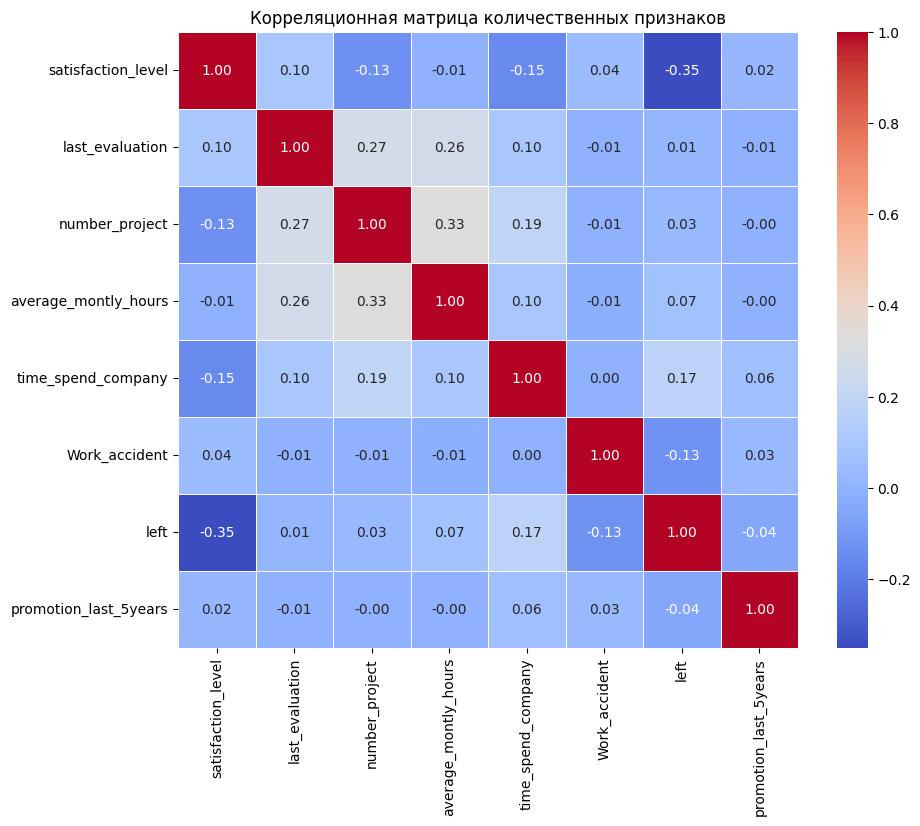

In [10]:
# Матрица корреляции
corr = df_clean.corr(numeric_only=True)

# Визуализация на тепловой карте
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', linewidths=.5)
plt.title('Корреляционная матрица количественных признаков')
plt.show()

## Вывод: ##

### Две самые скоррелированные переменные: ###

number_project и average_monthly_hours — 0.33. (Больше проектов, больше часов на работе)

last_evaluation и number_project — 0.27. (Сотрудники, выполняющие больше проектов, чаще получают более высокую оценку эффективности)

### Две наименее скоррелированные переменные ###

satisfaction_level и time_spend_company — -0.15 (Стаж работы слабо связан с уровнем удовлетворённост)

promotion_last_5years и average_monthly_hours — 0.00 (Количество отработанных часов почти не связано с вероятностью получения повышения)

### Связь с целевой переменной ###

Самая сильная связь у satisfaction_level и left — -0.35. Это подтверждает, что низкая удовлетворённость — одна из главных причин увольнений.

Слабая связь стажа и оттока: time_spend_company и left коррелируют на уровне 0.17

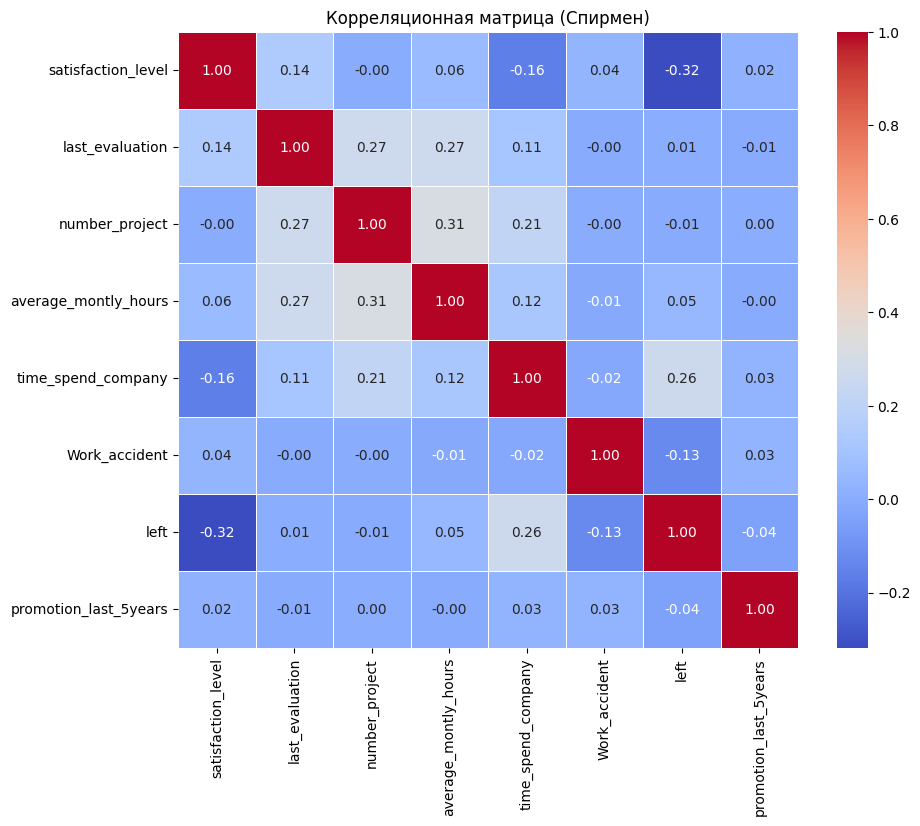

In [11]:
# Корреляция по Спирмену
spearman_corr = df_clean.corr(method='spearman', numeric_only=True)

plt.figure(figsize=(10, 8))
sns.heatmap(spearman_corr, annot=True, fmt='.2f', cmap='coolwarm', linewidths=.5)
plt.title('Корреляционная матрица (Спирмен)')
plt.show()

## 4. Cколько сотрудников работает в каждом департаменте ##

In [12]:
# Количество сотрудников в каждом департаменте
dept_counts = df_clean['department'].value_counts()
print(dept_counts)

department
sales          3239
technical      2244
support        1821
IT              976
RandD           694
product_mng     686
marketing       673
accounting      621
hr              601
management      436
Name: count, dtype: int64


## 5. Распределение сотрудников по зарплатам ##

In [13]:
# Подсчет количества сотрудникам  по зарплате
salary_counts = df_clean['salary'].value_counts()
print(salary_counts)

salary
low       5740
medium    5261
high       990
Name: count, dtype: int64


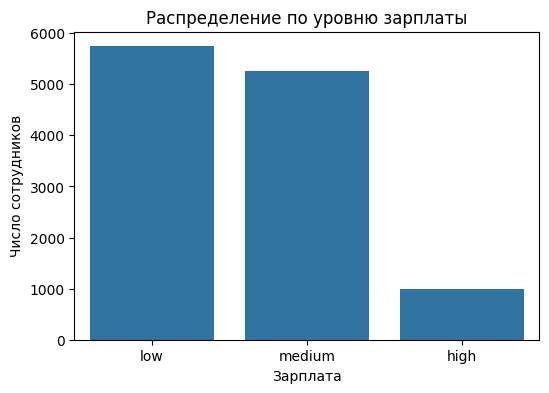

In [14]:
# Визуализация
plt.figure(figsize=(6, 4))
sns.countplot(data=df_clean, x='salary', order=['low', 'medium', 'high'])
plt.title('Распределение по уровню зарплаты')
plt.xlabel('Зарплата')
plt.ylabel('Число сотрудников')
plt.show()

##  6. Распределение по зарплатам в каждом департаменте отдельно ##

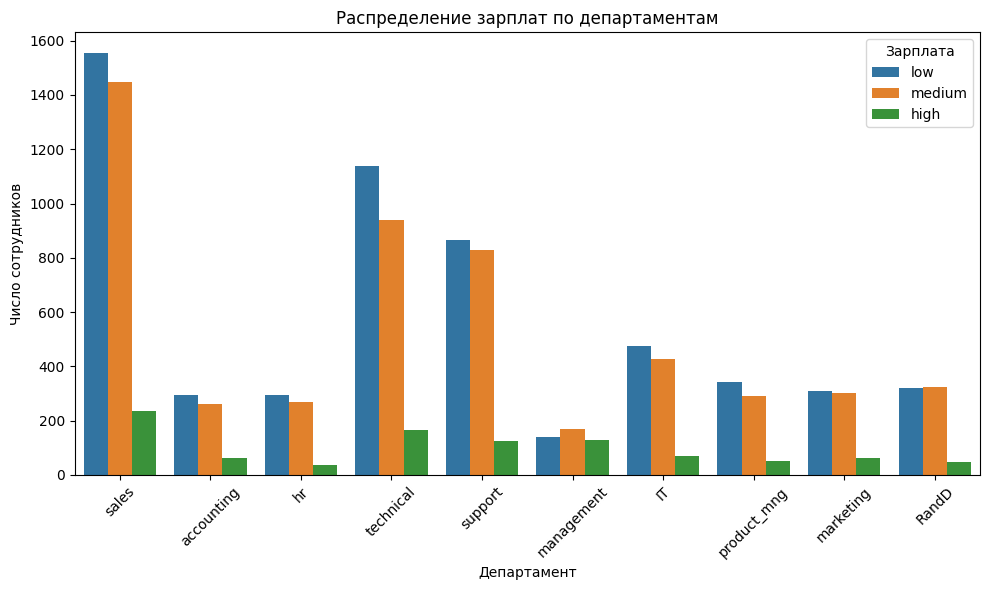

In [15]:
# Визуализация распределения по зарплатам в каждом департаменте
plt.figure(figsize=(10, 6))
sns.countplot(data=df_clean, x='department', hue='salary',
              hue_order=['low', 'medium', 'high'], dodge=True)
plt.xticks(rotation=45)
plt.title('Распределение зарплат по департаментам')
plt.xlabel('Департамент')
plt.ylabel('Число сотрудников')
plt.legend(title='Зарплата')
plt.tight_layout()
plt.show()

Крупнейшие по численности — sales, technical, support. В них сосредоточено подавляющее большинство сотрудников компании

Во всех департаментах преобладает доля сотрудников с зарплатами low и medium

В департаменте management доля high относительно выше, чем в технических или продажных отделах, что логично для руководящего звена.

## 7. Проверка гипотезы ##

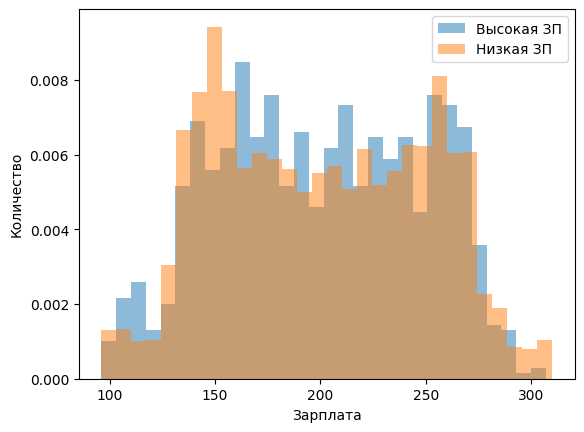

In [16]:
from scipy.stats import mannwhitneyu

# Подсчет сотрудников по зарплате
high_hours = df_clean[df_clean['salary'] == 'high']['average_montly_hours']
low_hours = df_clean[df_clean['salary'] == 'low']['average_montly_hours']

# Визулизация
plt.hist(high_hours, bins=30, alpha=0.5, label='Высокая ЗП', density=True)
plt.hist(low_hours, bins=30, alpha=0.5, label='Низкая ЗП', density=True)
plt.xlabel('Зарплата')
plt.ylabel('Количество')
plt.legend()
plt.show()


Признак заработной платы имеет частичную разделительную силу для этих групп, но не позволяет однозначно отнести наблюдение к одной из них. 

Для проверки проведем статистический тест Манна-Уитни

**Гипотезы:**

**Нулевая гипотеза:** Распределения отработанных часов (average_montly_hours) в группах с разным уровнем зарплаты (salary: low, high) не различаются. 

**Альтернативвная гипотеза:** Распределение отработанных часов различается. 

In [17]:
# Проводим стат тест
u_stat, u_pval = mannwhitneyu(high_hours, low_hours)

print(f"U-тест Манна-Уитни: U={u_stat:.1f}, p={u_pval:.4f}")

U-тест Манна-Уитни: U=2848437.0, p=0.8994


In [27]:
# Интерпретация
alpha = 0.05

if u_pval < alpha:
    print("Отклоняем нулевую гипотезу.")
    print("Есть статистически значимые основания считать, что распределение отработанных часов двух групп различаются.")
else:
    print("Не отклоняем нулевую гипотезу.")
    print("Недостаточно оснований считать, что распределение отработанных часов двух групп различаются.")

Не отклоняем нулевую гипотезу.
Недостаточно оснований считать, что распределение отработанных часов двух групп различаются.


## 8. Расчет показателей среди уволившихся и не уволившихся ##

In [19]:
# Расчет показателей (среднее бинарного признака повышения - доля, среднее по удовлетворенности и проектам)
grouped = df_clean.groupby('left').agg(
    share_prom=('promotion_last_5years', 'mean'),
    avg_satisfaction=('satisfaction_level', 'mean'),
    avg_projects=('number_project', 'mean')
)

grouped.index = grouped.index.map({0: 'Не уволились', 1: 'Уволились'})
grouped = grouped.round(3)
print(grouped)

              share_prom  avg_satisfaction  avg_projects
left                                                    
Не уволились       0.020             0.667         3.787
Уволились          0.004             0.440         3.883


**Вывод:**

*Доля сотрудников с повышением (share_prom)*

- Среди не уволившихся — 2 % имели повышение за последние 5 лет.
- Среди уволившихся — 0 % (точнее, 0.4 %, что практически нулевая доля).
- Повышения почти не встречались в обеих группах, но у уволившихся их было ещё меньше.

*Средняя удовлетворённость (avg_satisfaction)*

- У не уволившихся — 0.67, у уволившихся — 0.44.
- Уволившиеся сотрудники в среднем были существенно менее удовлетворены работой. 

*Среднее количество проектов (avg_projects)**

- Не уволившиеся — 3.79, уволившиеся — 3.88.
- Разница минимальна.


## 9. Разделение на выборки, LDA, оценка качества ##

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Признаки для модели (исключаем: department и salar)
feature_cols = ['satisfaction_level', 'last_evaluation', 'number_project',
               'average_montly_hours', 'time_spend_company',
               'Work_accident', 'promotion_last_5years']

# Выделение целевой переменной
X = df_clean[feature_cols]
y = df_clean['left']  

# Разделение (тест 20%)
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=42, stratify=y)

# Инициируем модель LDA
model = LinearDiscriminantAnalysis()

# Обучение на трейн датасете
model.fit(X_train, y_train)

# Предсказание (на двух выборках)
y_pred_train = model.predict(X_train)  
y_pred = model.predict(X_test)

# Оценка
acc_train = accuracy_score(y_train, y_pred_train)
acc = accuracy_score(y_test, y_pred)

print(f"Accuracy на обучении: {acc_train:.3f}")
print(f"Accuracy на тесте:    {acc:.3f}")

print("Classification report (test):")
print(classification_report(y_test, y_pred))


Accuracy на обучении: 0.830
Accuracy на тесте:    0.837
Classification report (test):
              precision    recall  f1-score   support

           0       0.87      0.95      0.91      2001
           1       0.52      0.26      0.34       398

    accuracy                           0.84      2399
   macro avg       0.69      0.61      0.63      2399
weighted avg       0.81      0.84      0.81      2399



Модель хорошо определяет тех, кто останется, но пропускает большую часть тех, кто реально увольняется.

Низкая полнота по классу оттока (recall = 0.26)

In [23]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion matrix:")
print(cm)

Confusion matrix:
[[1904   97]
 [ 295  103]]


## Вне задания ##

In [24]:
from imblearn.over_sampling import SMOTE

In [ ]:
# Баланстирование классов
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

# Обучение модели на сбалансированных данных
model = LinearDiscriminantAnalysis()
model.fit(X_train_res, y_train_res)

# Предсказание на тесте
y_pred = model.predict(X_test)

# Оценка
print(classification_report(y_test, y_pred))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.96      0.76      0.85      2001
           1       0.41      0.84      0.55       398

    accuracy                           0.77      2399
   macro avg       0.68      0.80      0.70      2399
weighted avg       0.87      0.77      0.80      2399

Confusion matrix:
 [[1513  488]
 [  63  335]]
